In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("Fisiere CSV gasite:")
for f in files:
    print(f)

fisier = next(
    f for f in files
    if "era5_modis_valcea_processed" in f
)

df = pd.read_csv(fisier)

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print(df.head())
print("\nDimensiuni:", df.shape)
print("\nColoane:", df.columns.tolist())

Fisiere CSV gasite:
/kaggle/input/datasets/marianursarescu/output-cp1-ic3/era5_modis_valcea_processed.csv
        date  temperature_c  soil_moisture  precipitation_mm      NDVI  month  \
0 2015-01-01     -13.684741       0.371719          0.003309  0.224061      1   
1 2015-01-02      -5.223634       0.370098          0.002842  0.224061      1   
2 2015-01-03       0.437639       0.371607          0.002564  0.224061      1   
3 2015-01-04       0.069644       0.374845          0.829599  0.224061      1   
4 2015-01-05      -2.093232       0.375143          0.002209  0.224061      1   

       mean       std      SSMI  
0  0.365848  0.032985  0.177978  
1  0.365848  0.032985  0.128832  
2  0.365848  0.032985  0.174599  
3  0.365848  0.032985  0.272751  
4  0.365848  0.032985  0.281778  

Dimensiuni: (4018, 9)

Coloane: ['date', 'temperature_c', 'soil_moisture', 'precipitation_mm', 'NDVI', 'month', 'mean', 'std', 'SSMI']


In [3]:
print("Perioada analizata:")
print(df["date"].min(), "-", df["date"].max())

print("\nValori lipsa:")
print(df.isnull().sum())

print("\nStatistici:")
print(df[
    ["temperature_c", "precipitation_mm",
     "soil_moisture", "NDVI", "SSMI"]
].describe())

Perioada analizata:
2015-01-01 00:00:00 - 2025-12-31 00:00:00

Valori lipsa:
date                0
temperature_c       0
soil_moisture       0
precipitation_mm    0
NDVI                0
month               0
mean                0
std                 0
SSMI                0
dtype: int64

Statistici:
       temperature_c  precipitation_mm  soil_moisture         NDVI  \
count    4018.000000       4018.000000    4018.000000  4018.000000   
mean       12.507980          0.572791       0.298016     0.530812   
std         9.010941          1.126001       0.075842     0.172245   
min       -14.317328          0.000000       0.133372     0.009903   
25%         4.909880          0.001743       0.239994     0.390752   
50%        12.504856          0.068458       0.316940     0.560080   
75%        20.499895          0.629851       0.357466     0.685808   
max        32.082687         15.358126       0.426143     0.797074   

              SSMI  
count  4018.000000  
mean     -0.284142  
std  

In [6]:
orizont = 28

df["SSMI_viitor"] = [
    df["SSMI"].iloc[i+1:i+29].mean()
    if i + 28 < len(df) else np.nan
    for i in range(len(df))
]

print(df[["date", "SSMI", "SSMI_viitor"]].head())

        date      SSMI  SSMI_viitor
0 2015-01-01  0.177978     0.740713
1 2015-01-02  0.128832     0.772646
2 2015-01-03  0.174599     0.803916
3 2015-01-04  0.272751     0.839268
4 2015-01-05  0.281778     0.880060


In [7]:
train = df[
    (df["date"] >= "2015-01-01") &
    (df["date"] < "2021-12-04")
].copy()

val = df[
    (df["date"] >= "2022-01-01") &
    (df["date"] < "2023-12-04")
].copy()

test = df[
    (df["date"] >= "2024-01-01") &
    (df["date"] < "2025-12-04")
].copy()

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

Train: 2529
Validation: 702
Test: 703


In [8]:
# Baseline pe validation
y_val = val["SSMI_viitor"]
pred_val = val["SSMI"]

mae_val = mean_absolute_error(y_val, pred_val)
rmse_val = np.sqrt(mean_squared_error(y_val, pred_val))

print("Baseline - Validation")
print("MAE:", round(mae_val, 4))
print("RMSE:", round(rmse_val, 4))

# Baseline pe test
y_test = test["SSMI_viitor"]
pred_test = test["SSMI"]

mae_test = mean_absolute_error(y_test, pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

print("\nBaseline - Test")
print("MAE:", round(mae_test, 4))
print("RMSE:", round(rmse_test, 4))

Baseline - Validation
MAE: 0.7101
RMSE: 0.8862

Baseline - Test
MAE: 0.6785
RMSE: 0.8416


In [9]:
variabile = [
    "temperature_c",
    "precipitation_mm",
    "soil_moisture",
    "NDVI",
    "SSMI"
]

for var in variabile:
    df[var + "_mean28"] = df[var].rolling(28).mean()
    df[var + "_std28"] = df[var].rolling(28).std()

# Precipitatii totale in ultimele 28 de zile
df["precipitation_sum28"] = (
    df["precipitation_mm"].rolling(28).sum()
)

features = [
    var + "_mean28" for var in variabile
] + [
    var + "_std28" for var in variabile
] + ["precipitation_sum28"]

print("Numar caracteristici:", len(features))

Numar caracteristici: 11


In [11]:
train_rf = df[
    (df["date"] >= "2015-01-01") &
    (df["date"] < "2021-12-04")
].copy()

val_rf = df[
    (df["date"] >= "2022-01-01") &
    (df["date"] < "2023-12-04")
].copy()

test_rf = df[
    (df["date"] >= "2024-01-01") &
    (df["date"] < "2025-12-04")
].copy()

train_rf = train_rf.dropna(subset=features + ["SSMI_viitor"])
val_rf = val_rf.dropna(subset=features + ["SSMI_viitor"])
test_rf = test_rf.dropna(subset=features + ["SSMI_viitor"])

X_train = train_rf[features]
y_train = train_rf["SSMI_viitor"]

X_val = val_rf[features]
y_val_rf = val_rf["SSMI_viitor"]

X_test = test_rf[features]
y_test_rf = test_rf["SSMI_viitor"]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (2502, 11)
Validation: (702, 11)
Test: (703, 11)


In [12]:
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

pred_rf_val = model.predict(X_val)
pred_rf_test = model.predict(X_test)

print("Random Forest antrenat!")

Random Forest antrenat!


In [13]:
rezultate = pd.DataFrame({
    "Model": [
        "Persistenta - Validation",
        "Random Forest - Validation",
        "Persistenta - Test",
        "Random Forest - Test"
    ],
    "MAE": [
        mae_val,
        mean_absolute_error(y_val_rf, pred_rf_val),
        mae_test,
        mean_absolute_error(y_test_rf, pred_rf_test)
    ],
    "RMSE": [
        rmse_val,
        np.sqrt(mean_squared_error(y_val_rf, pred_rf_val)),
        rmse_test,
        np.sqrt(mean_squared_error(y_test_rf, pred_rf_test))
    ]
})

print(rezultate.round(4))

                        Model     MAE    RMSE
0    Persistenta - Validation  0.7101  0.8862
1  Random Forest - Validation  0.7258  0.9390
2          Persistenta - Test  0.6785  0.8416
3        Random Forest - Test  1.0943  1.3080


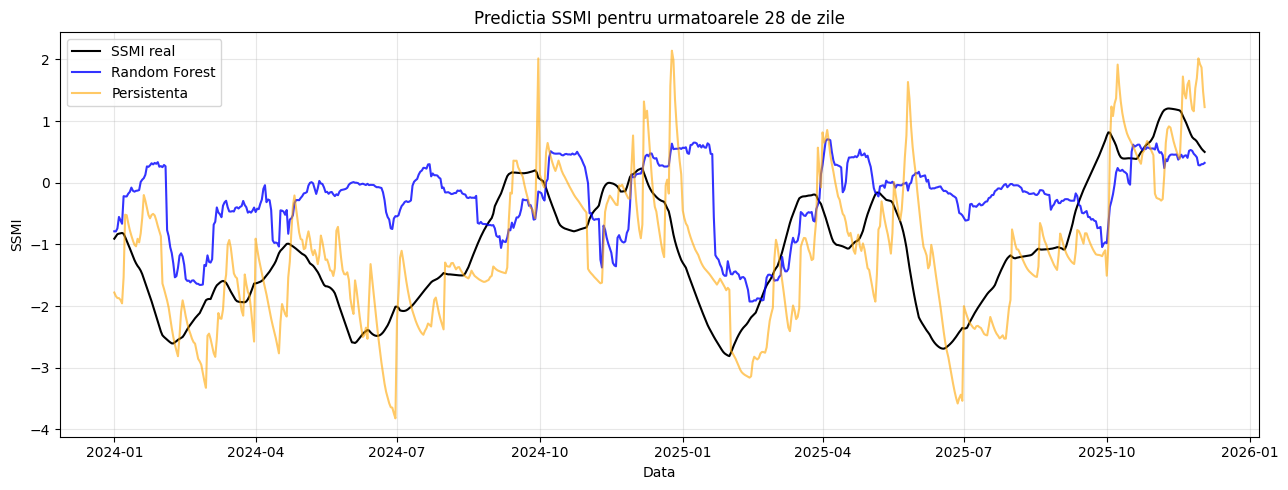

In [14]:
plt.figure(figsize=(13, 5))

plt.plot(
    test_rf["date"],
    y_test_rf,
    label="SSMI real",
    color="black"
)

plt.plot(
    test_rf["date"],
    pred_rf_test,
    label="Random Forest",
    color="blue",
    alpha=0.8
)

plt.plot(
    test_rf["date"],
    test_rf["SSMI"],
    label="Persistenta",
    color="orange",
    alpha=0.6
)

plt.title("Predictia SSMI pentru urmatoarele 28 de zile")
plt.xlabel("Data")
plt.ylabel("SSMI")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Am implementat două metode pentru predicția indicelui SSMI pe un orizont de 28 de zile: un baseline bazat pe persistență și un model Random Forest.

# Am utilizat un split temporal: 2015–2021 pentru antrenare, 2022–2023 pentru validare și 2024–2025 pentru testare.

# Pe setul de test, persistența a obținut MAE = 0,6785 și RMSE = 0,8416, în timp ce Random Forest a obținut MAE = 1,0943 și RMSE = 1,3080.

# Rezultatele arată că modelul Random Forest nu depășește încă baseline-ul, fiind necesară îmbunătățirea reprezentării datelor și analiza caracteristicilor utilizate.